In [1]:
import os
os.chdir(r"C:\Users\Alive\Documents\eeg-brain-networks-dementia")
print(os.getcwd())
os.makedirs("data/connectivity", exist_ok=True)

C:\Users\Alive\Documents\eeg-brain-networks-dementia


In [2]:
import mne, mne_connectivity
print(mne.__version__, mne_connectivity.__version__)

1.13.2 0.9.0


In [3]:
import numpy as np
from mne_connectivity import spectral_connectivity_epochs

FMIN = (1, 4, 8, 13, 30)
FMAX = (4, 8, 13, 30, 45)

def wpli_matrices(epochs):
    """Return an array (5 bands, 19, 19) of symmetric wPLI matrices."""
    con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
                                       fmin=FMIN, fmax=FMAX, faverage=True, verbose=False)
    m = con.get_data(output="dense")          # 19 x 19 x 5, lower triangle only
    m = np.moveaxis(m, -1, 0)                 # -> 5 x 19 x 19
    m = m + np.transpose(m, (0, 2, 1))        # make symmetric
    for b in range(m.shape[0]):
        np.fill_diagonal(m[b], 0)
    return m

ep = mne.read_epochs("data/epochs/sub-001-epo.fif", preload=True, verbose=False)
W = wpli_matrices(ep)
print(W.shape, W.min().round(3), W.max().round(3))
print("Symmetric:", np.allclose(W[2], W[2].T))
print("Mean wPLI per band:", W.mean(axis=(1, 2)).round(3))

C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\2117687711.py:9: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\2117687711.py:9: RuntimeWarning: fmin=1.000 Hz corresponds to 4.000 < 5 cycles based on the epoch length 4.000 sec, need at least 5.000 sec epochs or fmin=1.250. Spectrum estimate will be unreliable.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


(5, 19, 19) 0.0 0.621
Symmetric: True
Mean wPLI per band: [0.155 0.193 0.178 0.166 0.225]


In [4]:
import numpy as np, mne
from mne_connectivity import spectral_connectivity_epochs

BAND_NAMES = ["delta", "theta", "alpha", "beta", "gamma"]
FMIN = (1.25, 4, 8, 13, 30)
FMAX = (4, 8, 13, 30, 45)

def wpli_matrices(epochs):
    """Return an array (5 bands, 19, 19) of symmetric wPLI matrices."""
    con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",
                                       fmin=FMIN, fmax=FMAX, faverage=True, verbose=False)
    m = con.get_data(output="dense")
    m = np.moveaxis(m, -1, 0)
    m = m + np.transpose(m, (0, 2, 1))
    for b in range(m.shape[0]):
        np.fill_diagonal(m[b], 0)
    return m

offdiag = ~np.eye(19, dtype=bool)
for sub in ["sub-001", "sub-037", "sub-066"]:
    ep = mne.read_epochs(f"data/epochs/{sub}-epo.fif", preload=True, verbose=False)
    W = wpli_matrices(ep)
    np.save(f"data/connectivity/{sub}_wpli.npy", W)
    means = [W[b][offdiag].mean().round(3) for b in range(5)]
    print(sub, W.shape, "range", W.min().round(3), W.max().round(3),
          "| symmetric:", all(np.allclose(W[b], W[b].T) for b in range(5)),
          "| off-diagonal means:", means)

C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\105472964.py:10: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


sub-001 (5, 19, 19) range 0.0 0.621 | symmetric: True | off-diagonal means: [np.float64(0.159), np.float64(0.203), np.float64(0.188), np.float64(0.176), np.float64(0.238)]


C:\Users\Alive\AppData\Local\Temp\ipykernel_11032\105472964.py:10: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 60 events (all good), 0 – 3.998 s (baseline off), ~17.4 MiB, data loaded,
 '1': 60>, so metadata was not modified.
  con = spectral_connectivity_epochs(epochs, method="wpli", mode="multitaper",


sub-037 (5, 19, 19) range 0.0 0.65 | symmetric: True | off-diagonal means: [np.float64(0.147), np.float64(0.207), np.float64(0.308), np.float64(0.153), np.float64(0.136)]
sub-066 (5, 19, 19) range 0.0 0.491 | symmetric: True | off-diagonal means: [np.float64(0.138), np.float64(0.19), np.float64(0.209), np.float64(0.174), np.float64(0.196)]


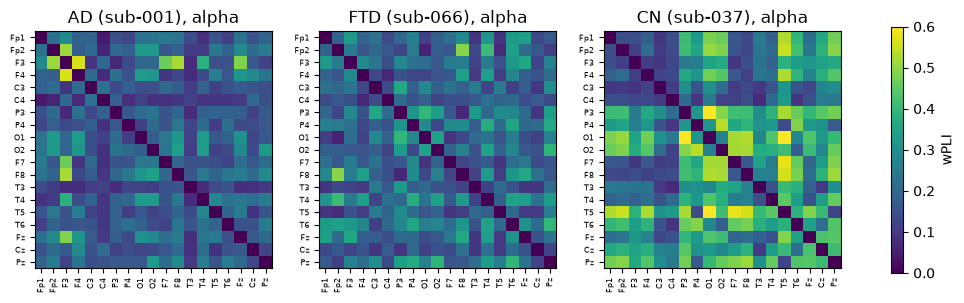

In [5]:
import matplotlib.pyplot as plt
os.makedirs("results/figures", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (sub, grp) in zip(axes, [("sub-001", "AD"), ("sub-066", "FTD"), ("sub-037", "CN")]):
    W = np.load(f"data/connectivity/{sub}_wpli.npy")
    im = ax.imshow(W[2], vmin=0, vmax=0.6, cmap="viridis")
    ax.set_title(f"{grp} ({sub}), alpha")
    ax.set_xticks(range(19)); ax.set_yticks(range(19))
    ax.set_xticklabels(ep.ch_names, rotation=90, fontsize=6)
    ax.set_yticklabels(ep.ch_names, fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8, label="wPLI")
plt.savefig("results/figures/test_subjects_wpli_alpha.png", dpi=150, bbox_inches="tight")
plt.show()